In [1]:
import numpy as np
import matplotlib.pyplot as plt
def f(x, t):
    return np.tan(x)-t
def df(x):
    return 1/(np.cos(x)**2) 

def newt(x0, target, t, maxIters=10 ): 
    x = x0
    iter = 0
    errors = []
    while iter < maxIters:
        err = abs(x - target)
        errors.append(err)
        fx = f(x, t)
        dfx = df(x)
        x = x - fx / dfx
        iter += 1
    return errors

def secant_method(x0, x1, target, t, maxIters=10):
    errors = []
    iter = 0
    while iter < maxIters:
        err = abs(x0-target)
        errors.append(err)
        fx0 = f(x0, t)
        fx1 = f(x1, t)
        if fx1-fx0 == 0:
            for i in range(0, maxIters-iter-1):
                errors.append(0)
            break
        x_next = x1 - fx1 * (x1 - x0) / (fx1 - fx0)
        x0, x1 = x1, x_next
        iter += 1
    return errors

In [2]:
newt(0.5, np.arctan(0.25), 0.25)

[np.float64(0.2550213368731359),
 np.float64(0.026823632702705075),
 np.float64(0.0001926983622183298),
 np.float64(9.287934865653824e-09),
 np.float64(5.551115123125783e-17),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0)]

In [3]:
secant_method(0.5, 1, np.arctan(0.25), 0.25)

[np.float64(0.2550213368731359),
 np.float64(0.7550213368731359),
 np.float64(0.10849727605213541),
 np.float64(0.04377463956333563),
 np.float64(0.001426384796508945),
 np.float64(1.655042206352708e-05),
 np.float64(5.913172146376766e-09),
 np.float64(2.450817326860033e-14),
 np.float64(0.0),
 0]

In [4]:
newt_err = newt(0.5, np.arctan(0.5), 0.5)

In [5]:
sec_err = secant_method(0.5, 1, np.arctan(0.5), 0.5)

Newtons method is better because it converges quicker, but this is because it is using the derivative to make the next guess which is more effeicent than estimating with secant method

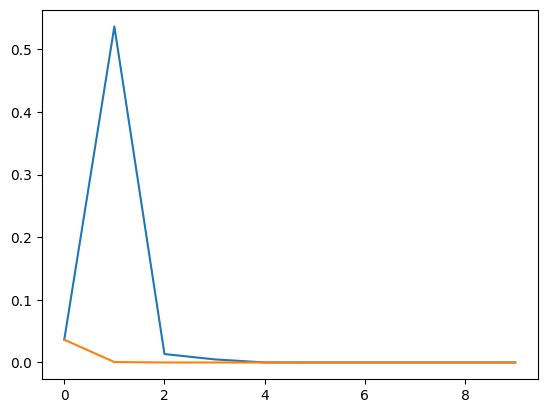

In [6]:
iterations = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
plt.plot(iterations, sec_err)
plt.plot(iterations, newt_err)

In [20]:
import numpy as np
import matplotlib.pyplot as plt
def f(x, t):
    return np.tan(x)-t
def df(x):
    return 1/(np.cos(x)**2) 

def newt2(x0, target, t, maxIters=10 ): 
    x = x0
    iter = 0
    to_plot = []
    while iter < maxIters:
        to_plot.append(20*np.log10(abs((x-target)/target)))
        fx = f(x, t)
        dfx = df(x)
        x = x - fx / dfx
        iter += 1
    return to_plot

def secant_method2(x0, x1, target, t, maxIters=10):
    to_plot = []
    iter = 0
    while iter < maxIters:
        fx0 = f(x0, t)
        fx1 = f(x1, t)
        if fx1-fx0 == 0:
            for i in range(0, maxIters-iter):
                to_plot.append(to_plot[iter-1])
            break
        to_plot.append(20*np.log10(abs((x0-target)/target)))
        x_next = x1 - fx1 * (x1 - x0) / (fx1 - fx0)
        x0, x1 = x1, x_next
        iter += 1
    return to_plot

C:\Users\Brandon\AppData\Local\Temp\ipykernel_9436\1540527845.py:13: RuntimeWarning: divide by zero encountered in log10
  to_plot.append(20*np.log10(abs((x-target)/target)))


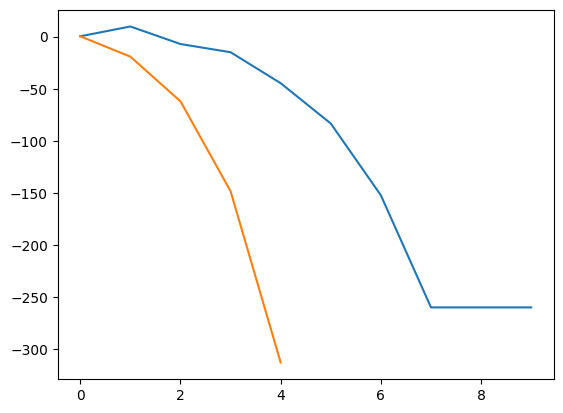

In [21]:
newt_log = newt2(0.5, np.arctan(0.25), 0.25)
to_plot = secant_method2(0.5, 1, np.arctan(0.25), 0.25)
plt.plot(iterations, to_plot)
plt.plot(iterations, newt_log)

In [22]:
from PIL import Image
import numpy as np
image = Image.open("Slime_Rimuru.png").convert("RGB")
img_np = np.array(image)
r, g, b = img_np[:,:,0], img_np[:,:,1], img_np[:,:,2]
gray_array = 0.3 * r + 0.6 * g + 0.1 * b
gray_array = np.clip(gray_array, 0, 255).astype(np.uint8)
gray_img = Image.fromarray(gray_array)
resized_img = gray_img.resize((256, 256))
resized_img.show()
resized_array = np.array(resized_img)


In [11]:
column1 = resized_array[:, 1]
column2 = resized_array[:, 2]
mean_X1 = np.mean(column1)
mean_Y1 = np.mean(column2)
r1 = (np.sum((column1 - mean_X1) * (column2 - mean_Y1)))/(np.sqrt(np.sum((column1 - mean_X1)**2) * np.sum((column2 - mean_Y1)**2)))
print(r1)

column3 = resized_array[:, 3]
column4 = resized_array[:, 4]
mean_X2 = np.mean(column3)
mean_Y2 = np.mean(column4)
r2 = (np.sum((column3 - mean_X2) * (column4 - mean_Y2)))/(np.sqrt(np.sum((column3 - mean_X2)**2) * np.sum((column4 - mean_Y2)**2)))
print(r2)

column5 = resized_array[:, 5]
column6 = resized_array[:, 6]
mean_X3 = np.mean(column5)
mean_Y3 = np.mean(column6)
r3 = (np.sum((column5 - mean_X3) * (column6 - mean_Y3)))/(np.sqrt(np.sum((column5 - mean_X3)**2) * np.sum((column6 - mean_Y3)**2)))
print(r3)


0.9055310860033428
0.9465773252600727
0.962361526976613


In [12]:
resized_array.shape

(256, 256)

In [26]:
len(resized_array[i, :])

256

In [27]:
compressed = resized_array[:, ::2]

In [29]:
decompressed = np.repeat(compressed, 2, axis=1)

In [30]:
new_img = Image.fromarray(decompressed)
new_img.show()

In [16]:
np.linalg.norm(resized_img) - np.linalg.norm(decompressed)

np.float64(30.624421492397232)

In [168]:
import pandas as pd
subject_labels = pd.read_csv("GSE39428_series_matrix.csv", skiprows=26, nrows=0, sep='\t')
thingy = list(subject_labels.columns)
data_labels = ['Diagnosis']
for string in thingy:
    if "ankylosing" not in string:
        if "health" in string:
            data_labels.append(0)
        else:
            data_labels.append(1)
df = pd.read_csv("GSE39428_series_matrix.csv", skiprows=58, sep='\t')
df = df.drop(df.columns[1:52], axis=1)
df = df.drop(df.index[-1])
df.loc[len(df)] = data_labels
rows, columns = df.shape

#Part b:
mapping = {"AA": 0, "AB": 1, "BB": 2, "NC": np.nan}
df = df.replace(mapping)
NC = df.isna().mean()
reliable_snps = NC[NC < 0.10].index
df_filtered = df[reliable_snps]
df_final = df_filtered[df_filtered.std(axis=1, numeric_only=True) > 0]

#Part c:
df_final.iloc[:-1, 1:] = df_final.iloc[:-1, 1:].apply(lambda x: x.fillna(x.mean()), axis=1)
df_final = pd.DataFrame(df_final.T)
df_final.columns = df_final.iloc[0]
df_final = df_final.drop(df_final.index[0])
df_final = df_final.reset_index()
y_labels = df_final['Diagnosis'].values
df_final = df_final.drop(columns=['index'])

C:\Users\Brandon\AppData\Local\Temp\ipykernel_9436\2036287220.py:19: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace(mapping)


In [170]:
df_final['Diagnosis'].value_counts()

Diagnosis
1.0    66
0.0    19
Name: count, dtype: int64

In [146]:
df_RA = df_final.loc[df_final['Diagnosis'] == 1]
RA_y = df_RA['Diagnosis'].values
df_RA = df_RA.drop(columns=['Diagnosis'])
df_healthy = df_final.loc[df_final['Diagnosis'] == 0]
healthy_y = df_healthy['Diagnosis'].values
df_healthy = df_healthy.drop(columns=['Diagnosis'])
from sklearn.model_selection import train_test_split
x_ra_train, X_ra_test, y_ra_train, Y_ra_test = train_test_split(df_RA, RA_y, test_size=0.2, random_state=2, shuffle=True)
x_healthy_train, X_healthy_test, y_healthy_train, Y_healthy_test = train_test_split(df_healthy, healthy_y, test_size=0.2, random_state=3)
train_set = pd.concat([x_ra_train ,x_healthy_train])
train_set_labels = np.concatenate([y_ra_train, y_healthy_train])
test_set = pd.concat([X_ra_test, X_healthy_test])
test_set_labels = np.concatenate([Y_ra_test, Y_healthy_test])


In [160]:
df_final

ID_REF,rs1002788,rs1005753,rs1006273,rs10152164,rs10184179,rs1032551,rs1039037,rs10400863,rs1042127,rs1043784,...,rs9405369,rs9406071,rs9502657,rs9505298,rs9505300,rs9505301,rs9505309,rs9505351,rs9896319,rs9906499
0,0.0,1.0,2.0,0.0,2.0,2.0,0.0,0.0,0.0,0.0,...,1.0,1.0,1.0,2.0,0.0,0.0,0.0,1.0,2.0,1.0
1,0.0,0.0,2.0,0.0,2.0,2.0,0.0,1.0,0.0,0.0,...,2.0,0.0,1.0,2.0,0.0,0.0,2.0,2.0,2.0,2.0
2,0.0,0.0,2.0,0.0,2.0,1.0,0.0,0.0,0.0,1.0,...,2.0,0.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0
3,0.0,0.0,1.0,0.0,2.0,1.0,1.0,0.0,1.0,0.0,...,2.0,2.0,1.0,1.0,0.38961,0.0,0.0,2.0,1.0,2.0
4,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,...,2.0,0.0,1.0,2.0,0.38961,0.0,0.0,1.0,1.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,0.0,1.0,2.0,0.0,2.0,1.0,0.0,2.0,0.0,0.0,...,1.0,1.0,1.0,1.0,0.0,0.0,2.0,1.0,2.0,2.0
81,0.0,1.0,0.0,2.0,2.0,2.0,1.0,2.0,0.0,0.0,...,1.0,1.0,1.0,2.0,0.0,0.0,1.0,2.0,2.0,2.0
82,0.0,1.0,2.0,0.0,2.0,2.0,0.0,2.0,0.0,0.0,...,2.0,1.0,1.0,2.0,0.0,0.0,1.0,2.0,1.0,2.0
83,0.0,0.0,1.380952,1.0,2.0,0.0,1.0,2.0,1.0,1.0,...,0.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0


In [166]:
df_RA

ID_REF,rs1002788,rs1005753,rs1006273,rs10152164,rs10184179,rs1032551,rs1039037,rs10400863,rs1042127,rs1043784,...,rs9405369,rs9406071,rs9502657,rs9505298,rs9505300,rs9505301,rs9505309,rs9505351,rs9896319,rs9906499
19,0.0,1.0,1.0,1.0,2.0,1.0,0.0,2.0,0.0,0.0,...,0.0,0.0,1.0,2.0,1.0,0.0,0.0,0.0,2.0,2.0
20,0.0,0.0,1.0,1.0,2.0,2.0,1.0,2.0,0.0,0.0,...,1.0,0.0,1.0,2.0,0.0,0.0,0.0,1.0,2.0,2.0
21,0.0,0.0,2.0,2.0,2.0,1.0,1.0,2.0,1.0,0.0,...,1.0,1.0,1.0,2.0,0.0,0.0,1.0,1.0,1.0,1.0
22,1.0,0.0,1.0,1.0,2.0,1.0,2.0,1.0,0.0,0.0,...,1.0,2.0,1.0,2.0,1.0,0.0,1.0,1.0,2.0,2.0
23,0.0,0.0,2.0,0.0,2.0,1.0,0.0,2.0,1.0,0.0,...,2.0,0.0,1.0,2.0,1.0,0.0,0.0,2.0,2.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,0.0,1.0,2.0,0.0,2.0,1.0,0.0,2.0,0.0,0.0,...,1.0,1.0,1.0,1.0,0.0,0.0,2.0,1.0,2.0,2.0
81,0.0,1.0,0.0,2.0,2.0,2.0,1.0,2.0,0.0,0.0,...,1.0,1.0,1.0,2.0,0.0,0.0,1.0,2.0,2.0,2.0
82,0.0,1.0,2.0,0.0,2.0,2.0,0.0,2.0,0.0,0.0,...,2.0,1.0,1.0,2.0,0.0,0.0,1.0,2.0,1.0,2.0
83,0.0,0.0,1.380952,1.0,2.0,0.0,1.0,2.0,1.0,1.0,...,0.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0


In [167]:
df_healthy

ID_REF,rs1002788,rs1005753,rs1006273,rs10152164,rs10184179,rs1032551,rs1039037,rs10400863,rs1042127,rs1043784,...,rs9405369,rs9406071,rs9502657,rs9505298,rs9505300,rs9505301,rs9505309,rs9505351,rs9896319,rs9906499
0,0.0,1.0,2.0,0.0,2.0,2.0,0.0,0.0,0.0,0.0,...,1.0,1.0,1.0,2.0,0.0,0.0,0.0,1.0,2.0,1.0
1,0.0,0.0,2.0,0.0,2.0,2.0,0.0,1.0,0.0,0.0,...,2.0,0.0,1.0,2.0,0.0,0.0,2.0,2.0,2.0,2.0
2,0.0,0.0,2.0,0.0,2.0,1.0,0.0,0.0,0.0,1.0,...,2.0,0.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0
3,0.0,0.0,1.0,0.0,2.0,1.0,1.0,0.0,1.0,0.0,...,2.0,2.0,1.0,1.0,0.38961,0.0,0.0,2.0,1.0,2.0
4,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,...,2.0,0.0,1.0,2.0,0.38961,0.0,0.0,1.0,1.0,2.0
5,0.0,0.0,1.0,0.0,2.0,1.0,1.0,2.0,0.0,0.0,...,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0
6,0.0,1.0,1.0,0.0,2.0,1.177215,1.0,1.0,0.0,1.0,...,2.0,0.0,1.0,2.0,1.0,1.0,0.0,2.0,0.0,2.0
7,0.0,0.0,1.0,2.0,2.0,2.0,1.0,2.0,0.0,0.0,...,2.0,1.0,1.0,2.0,0.0,0.0,1.0,2.0,2.0,1.0
8,0.0,0.0,2.0,0.0,2.0,2.0,1.0,1.0,0.0,1.0,...,2.0,0.0,1.0,2.0,0.0,1.0,0.0,2.0,2.0,2.0
9,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,2.0


In [148]:
def GWAS(df_final_func, y_labels):
    #Part d:
    df_normalized = (df_final_func-df_final_func.mean())/df_final_func.std()
    SNPS = list(df_normalized.columns)
    y_labels = np.array(y_labels).astype(float)
    results = []
    for snp in SNPS:
        x = np.array(df_normalized[snp]).astype(float)
        y = y_labels
        A = np.column_stack((np.ones(len(y_labels)), x))
        beta0, beta_i = np.linalg.lstsq(A, y_labels, rcond=None)[0]
        results.append([snp, beta_i+beta0])
    results.sort(key=lambda x: x[1])

    #Part e:
    remaining_snps = list(df_normalized.columns)
    groups = {}
    snp_reps = []
    group_counter = 1


    while len(remaining_snps) > 0:
        lead_snp = remaining_snps[0]
        vec_a = df_final_func[lead_snp].values.astype(float)
        norm_a = np.linalg.norm(vec_a)
        group_members = []
        for target_snp in remaining_snps:
            vec_b = df_final_func[target_snp].values.astype(float)
            norm_b = np.linalg.norm(vec_b)
            corr = np.dot(vec_a, vec_b) / (norm_a * norm_b)
            if abs(corr) > 0.7:
                group_members.append(target_snp)
        groups[f"Group_{group_counter}"] = {
            "representative": lead_snp,
            "members": group_members,
        }
    
        remaining_snps = [snp for snp in remaining_snps if snp not in group_members]
        group_counter += 1
        snp_reps.append([lead_snp, group_counter])


    results2 = []
    for snp, group in snp_reps:
        x = ((df_final_func[snp] - df_final_func[snp].mean()) / df_final_func[snp].std()).astype(float)
        y = y_labels
        A = np.column_stack((np.ones(len(y_labels)), x))
        beta0, beta_i = np.linalg.lstsq(A, y_labels, rcond=None)[0]
        results2.append([snp, beta_i+beta0, group])
    results2.sort(key=lambda x: x[1])
    
    #Part f:
    X = df_final_func.values  
    ones_column = np.ones((X.shape[0], 1))
    A = np.hstack([ones_column, X]).astype(float)
    beta_hat, residuals, rank, s = np.linalg.lstsq(A, y_labels, rcond=None)
    predicted_y = A @ beta_hat
    top_5_indices = sorted(range(len(beta_hat)), key=lambda i: beta_hat[i], reverse=True)[:5]
    top_thingies = df_final_func.columns[top_5_indices].tolist()

    df_plot = df_final_func.copy()
    df_plot['Diagnosis'] = y_labels
    df_plot['Predicted f(x)'] = predicted_y
    import seaborn as sns
    sns.stripplot(
    data=df_plot, 
    x='Diagnosis', 
    y='Predicted f(x)', 
    hue='Diagnosis',          
    palette='Set2',        
    jitter=0.25,           
    size=6,                
    alpha=0.7,             
    legend=False           
                )
    plt.show()
    
    X_reduced = df_normalized[top_thingies].values  
    ones_column = np.ones((X_reduced.shape[0], 1))
    A_reduced = np.hstack([ones_column, X_reduced]).astype(float)
    beta_reduced, _, _, _ = np.linalg.lstsq(A_reduced, y_labels, rcond=None)
    df_plot2 = df_plot.copy()
    df_plot2['f_x_reduced'] = A_reduced @ beta_reduced
    sns.stripplot(
        data=df_plot2, 
        x='Diagnosis',               
        y='f_x_reduced', 
        hue='Diagnosis',             
        palette='Set2', 
        jitter=0.25,              
        size=6, 
        alpha=0.7, 
        legend=False
                    )
    return top_thingies, beta_reduced


In [153]:
zero_std_cols = train_set.columns[train_set.std() == 0].tolist()
print("Constant columns:", zero_std_cols)

Constant columns: ['rs28633683']


In [154]:
train_set = train_set.drop(columns=['rs28633683'])
test_set = test_set.drop(columns=['rs28633683'])
#there is onlyone subject that does not have a 1 for this gene, so it is cumbersome to try and normalize so I am dropping it

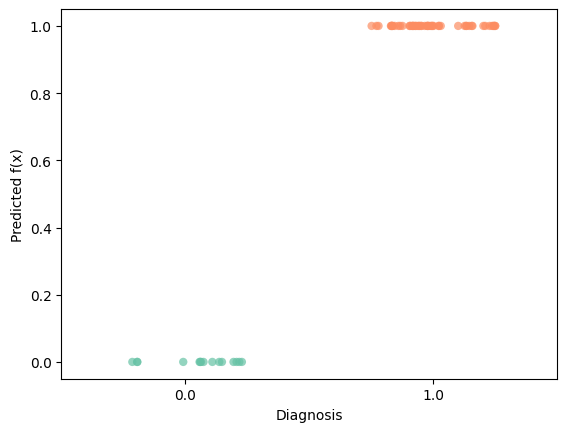

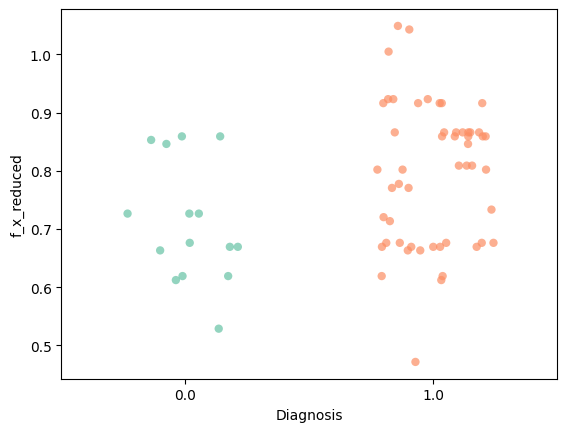

In [155]:
top_indicies, betas = GWAS(train_set, train_set_labels)

<Axes: xlabel='Diagnosis', ylabel='f_x_reduced'>

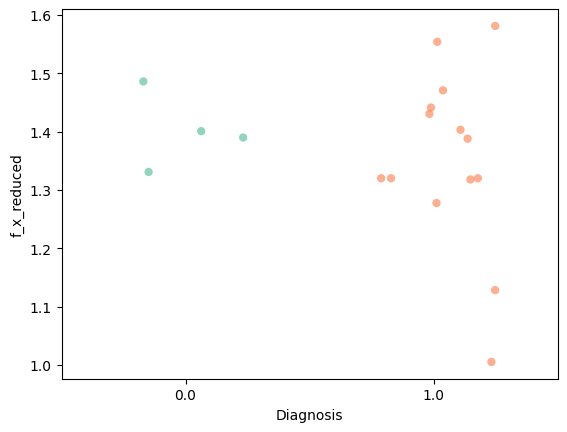

In [159]:
import seaborn as sns
X_reduced = test_set[top_indicies].values  
ones_column = np.ones((X_reduced.shape[0], 1))
A_reduced = np.hstack([ones_column, X_reduced]).astype(float)
cofs = betas
df_plot2 = test_set.copy()
df_plot2['Diagnosis'] = test_set_labels
df_plot2['f_x_reduced'] = A_reduced @ cofs
sns.stripplot(
    data=df_plot2, 
    x='Diagnosis',               
    y='f_x_reduced', 
    hue='Diagnosis',             
    palette='Set2', 
    jitter=0.25,              
    size=6, 
    alpha=0.7, 
    legend=False
                )

In [ ]:
fold1_RA = df_RA.iloc[0:13, :]
fold2_RA = df_RA.iloc[13:26, :]
fold3_RA = df_RA.iloc[26:39, :]
fold4_RA = df_RA.iloc[39:52]
fold5_RA = df_RA.iloc[52:, :]

fold1_healthy = df_healthy.iloc[0:3, :]
fold2_healthy = df_healthy.iloc[3:6, :]
fold3_healthy = df_healthy.iloc[6:9, :]
fold4_healthy = df_healthy.iloc[9:12, :]
fold5_healthy = df_healthy.iloc[12:, :]

fold1 = pd.concat([fold1_RA, fold1_healthy])
fold2 = pd.concat([fold2_RA, fold2_healthy])
fold3 = pd.concat([fold3_RA, fold1_healthy])
fold4 = pd.concat([fold4_RA, fold4_healthy])
fold5 = pd.concat([fold5_RA, fold5_healthy])



In [179]:
fold1_labels = np.concatenate([RA_y[0:13], healthy_y[0:3]])
fold2_labels = np.concatenate([RA_y[13:26], healthy_y[3:6]])
fold3_labels = np.concatenate([RA_y[26:39], healthy_y[6:9]])
fold4_labels = np.concatenate([RA_y[39:52], healthy_y[9:12]])
fold5_labels = np.concatenate([RA_y[52:], healthy_y[12:]])

In [ ]:
def better_GWAS(train_df, train_lables, test_df, test_labels):
    #Part d:
    df_normalized = (df_final_func-df_final_func.mean())/df_final_func.std()
    SNPS = list(df_normalized.columns)
    y_labels = np.array(y_labels).astype(float)
    results = []
    for snp in SNPS:
        x = np.array(df_normalized[snp]).astype(float)
        y = y_labels
        A = np.column_stack((np.ones(len(y_labels)), x))
        beta0, beta_i = np.linalg.lstsq(A, y_labels, rcond=None)[0]
        results.append([snp, beta_i+beta0])
    results.sort(key=lambda x: x[1])

    #Part e:
    remaining_snps = list(df_normalized.columns)
    groups = {}
    snp_reps = []
    group_counter = 1


    while len(remaining_snps) > 0:
        lead_snp = remaining_snps[0]
        vec_a = df_final_func[lead_snp].values.astype(float)
        norm_a = np.linalg.norm(vec_a)
        group_members = []
        for target_snp in remaining_snps:
            vec_b = df_final_func[target_snp].values.astype(float)
            norm_b = np.linalg.norm(vec_b)
            corr = np.dot(vec_a, vec_b) / (norm_a * norm_b)
            if abs(corr) > 0.7:
                group_members.append(target_snp)
        groups[f"Group_{group_counter}"] = {
            "representative": lead_snp,
            "members": group_members,
        }
    
        remaining_snps = [snp for snp in remaining_snps if snp not in group_members]
        group_counter += 1
        snp_reps.append([lead_snp, group_counter])


    results2 = []
    for snp, group in snp_reps:
        x = ((df_final_func[snp] - df_final_func[snp].mean()) / df_final_func[snp].std()).astype(float)
        y = y_labels
        A = np.column_stack((np.ones(len(y_labels)), x))
        beta0, beta_i = np.linalg.lstsq(A, y_labels, rcond=None)[0]
        results2.append([snp, beta_i+beta0, group])
    results2.sort(key=lambda x: x[1])
    
    #Part f:
    X = df_final_func.values  
    ones_column = np.ones((X.shape[0], 1))
    A = np.hstack([ones_column, X]).astype(float)
    beta_hat, residuals, rank, s = np.linalg.lstsq(A, y_labels, rcond=None)
    predicted_y = A @ beta_hat
    top_5_indices = sorted(range(len(beta_hat)), key=lambda i: beta_hat[i], reverse=True)[:5]
    top_thingies = df_final_func.columns[top_5_indices].tolist()

    df_plot = df_final_func.copy()
    df_plot['Diagnosis'] = y_labels
    df_plot['Predicted f(x)'] = predicted_y
    import seaborn as sns
    sns.stripplot(
    data=df_plot, 
    x='Diagnosis', 
    y='Predicted f(x)', 
    hue='Diagnosis',          
    palette='Set2',        
    jitter=0.25,           
    size=6,                
    alpha=0.7,             
    legend=False           
                )
    plt.show()
    
    X_reduced = df_normalized[top_thingies].values  
    ones_column = np.ones((X_reduced.shape[0], 1))
    A_reduced = np.hstack([ones_column, X_reduced]).astype(float)
    beta_reduced, _, _, _ = np.linalg.lstsq(A_reduced, y_labels, rcond=None)
    df_plot2 = df_plot.copy()
    df_plot2['f_x_reduced'] = A_reduced @ beta_reduced
    sns.stripplot(
        data=df_plot2, 
        x='Diagnosis',               
        y='f_x_reduced', 
        hue='Diagnosis',             
        palette='Set2', 
        jitter=0.25,              
        size=6, 
        alpha=0.7, 
        legend=False
                    )
    return top_thingies, beta_reduced
